In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("employees.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,id,name,department,salary
0,1,Arun,IT,55000
1,2,Priya,HR,42000
2,3,Karthik,Finance,48000
3,4,Divya,IT,62000
4,5,Ravi,Sales,40000


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(20, 4)

Column Names:
Index(['id', 'name', 'department', 'salary'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          20 non-null     int64
 1   name        20 non-null     str  
 2   department  20 non-null     str  
 3   salary      20 non-null     int64
dtypes: int64(2), str(2)
memory usage: 772.0 bytes

Missing Values:
id            0
name          0
department    0
salary        0
dtype: int64


In [5]:
print("Total Duplicate Records:")
print(df.duplicated().sum())

Total Duplicate Records:
0


In [6]:
df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Total Rows:", len(df))

Duplicate records removed successfully!
Total Rows: 20


In [7]:
# Remove extra spaces and standardize text

df['name'] = df['name'].str.strip().str.title()

df['department'] = df['department'].str.strip().str.title()

print("Text standardization completed!")

df.head()

Text standardization completed!


,id,name,department,salary
0,1,Arun,It,55000
1,2,Priya,Hr,42000
2,3,Karthik,Finance,48000
3,4,Divya,It,62000
4,5,Ravi,Sales,40000


In [8]:
print("Before Data Type Correction:")
print(df.dtypes)

Before Data Type Correction:
id            int64
name            str
department      str
salary        int64
dtype: object


In [9]:
# Detect outliers using IQR method

Q1 = df['salary'].quantile(0.25)

Q3 = df['salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df['salary'] < lower_limit) |
    (df['salary'] > upper_limit)
]

print("\nOutlier Records:")
print(outliers)

Q1: 44750.0
Q3: 56250.0
IQR: 11500.0
Lower Limit: 27500.0
Upper Limit: 73500.0

Outlier Records:
Empty DataFrame
Columns: [id, name, department, salary]
Index: []


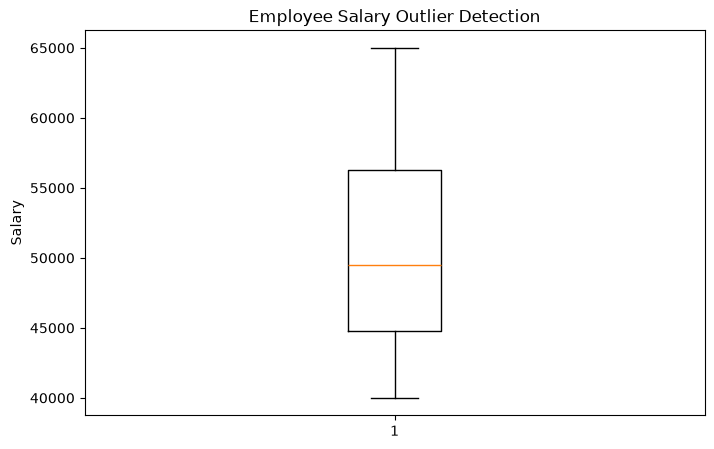

In [10]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['salary'])

plt.title("Employee Salary Outlier Detection")

plt.ylabel("Salary")

plt.show()

In [11]:
# Before and After Data Cleaning Summary

summary = pd.DataFrame({
    'Description': [
        'Total Rows',
        'Missing Values',
        'Duplicate Records'
    ],
    'Before Cleaning': [
        20,
        0,
        0
    ],
    'After Cleaning': [
        len(df),
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

print("Before and After Data Cleaning Summary")

summary

Before and After Data Cleaning Summary


,Description,Before Cleaning,After Cleaning
0,Total Rows,20,20
1,Missing Values,0,0
2,Duplicate Records,0,0


In [12]:
df.to_csv("clean_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [13]:
# Summary Statistics

print("Employee Salary Summary")

salary_summary = df['salary'].agg([
    'mean',
    'median',
    'min',
    'max',
    'std'
])

print(salary_summary)

Employee Salary Summary
mean      50700.000000
median    49500.000000
min       40000.000000
max       65000.000000
std        7392.029847
Name: salary, dtype: float64


In [14]:
# Department-wise Salary Analysis

department_salary = df.groupby('department')['salary'].agg([
    'count',
    'mean',
    'min',
    'max'
])

print("Department-wise Salary Analysis")

department_salary

Department-wise Salary Analysis


,count,mean,min,max
department,,,,
Finance,5,52000.0,48000,56000
Hr,4,44500.0,42000,47000
It,6,59500.0,55000,65000
Sales,5,43800.0,40000,49000


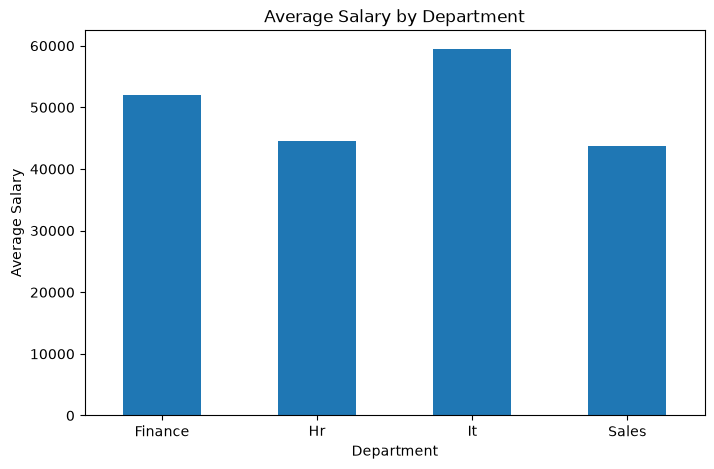

In [15]:
# Department-wise Average Salary Chart

department_salary['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Average Salary by Department")

plt.xlabel("Department")

plt.ylabel("Average Salary")

plt.xticks(rotation=0)

plt.show()

In [16]:
# Correlation Analysis

correlation = df[['id', 'salary']].corr()

print("Correlation Between Numerical Columns")

print(correlation)

Correlation Between Numerical Columns
             id   salary
id      1.00000  0.11313
salary  0.11313  1.00000


In [17]:
# Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Employee Data Correlation")

plt.show()

ModuleNotFoundError: No module named 'seaborn'

In [18]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


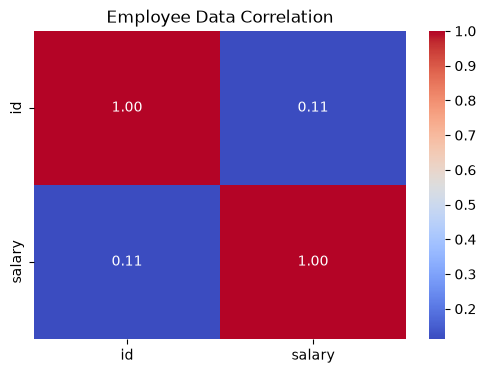

In [19]:
# Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Employee Data Correlation")

plt.show()

In [20]:
# Business Questions and Answers

# Question 1: What is the average employee salary?
print("1. Average Employee Salary:")
print(df['salary'].mean())

# Question 2: Which department has the highest average salary?
print("\n2. Department with Highest Average Salary:")
print(df.groupby('department')['salary'].mean().idxmax())

# Question 3: What is the highest employee salary?
print("\n3. Highest Employee Salary:")
print(df['salary'].max())

# Question 4: What is the lowest employee salary?
print("\n4. Lowest Employee Salary:")
print(df['salary'].min())

# Question 5: How many employees are in each department?
print("\n5. Employees in Each Department:")
print(df['department'].value_counts())

1. Average Employee Salary:
50700.0

2. Department with Highest Average Salary:
It

3. Highest Employee Salary:
65000

4. Lowest Employee Salary:
40000

5. Employees in Each Department:
department
It         6
Finance    5
Sales      5
Hr         4
Name: count, dtype: int64


In [21]:
# Create Department Budget Table

budget_data = {
    'department': ['It', 'Hr', 'Finance', 'Sales'],
    'budget': [500000, 300000, 450000, 350000]
}

budget_df = pd.DataFrame(budget_data)

print("Department Budget Table")

budget_df

Department Budget Table


,department,budget
0,It,500000
1,Hr,300000
2,Finance,450000
3,Sales,350000


In [22]:
# Merge Employee Data with Department Budget

merged_df = pd.merge(
    df,
    budget_df,
    on='department',
    how='left'
)

print("Merged Employee and Department Budget Data")

merged_df.head(10)

Merged Employee and Department Budget Data


,id,name,department,salary,budget
0,1,Arun,It,55000,500000
1,2,Priya,Hr,42000,300000
2,3,Karthik,Finance,48000,450000
3,4,Divya,It,62000,500000
4,5,Ravi,Sales,40000,350000
5,6,Meena,Hr,45000,300000
6,7,Suresh,Finance,52000,450000
7,8,Anitha,It,58000,500000
8,9,Vijay,Sales,43000,350000
9,10,Nisha,Finance,50000,450000


In [23]:
# Create Salary Categories

df['salary_category'] = pd.cut(
    df['salary'],
    bins=[0, 45000, 55000, float('inf')],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

print("Salary Categories Created Successfully!")

df[['name', 'department', 'salary', 'salary_category']].head()

Salary Categories Created Successfully!


,name,department,salary,salary_category
0,Arun,It,55000,Medium
1,Priya,Hr,42000,Low
2,Karthik,Finance,48000,Medium
3,Divya,It,62000,High
4,Ravi,Sales,40000,Low


In [24]:
# Create Pivot Table

pivot_table = pd.pivot_table(
    df,
    index='department',
    columns='salary_category',
    values='id',
    aggfunc='count',
    fill_value=0,
    observed=False
)

print("Employee Department and Salary Category Pivot Table")

pivot_table

Employee Department and Salary Category Pivot Table


salary_category,Low,Medium,High
department,,,
Finance,0,4,1
Hr,3,1,0
It,0,1,5
Sales,3,2,0


## Conclusion

In this project, I completed employee data cleaning and exploratory data analysis using Python and Pandas.

- Checked and handled missing values.
- Removed duplicate records.
- Standardized employee names and department values.
- Checked data types.
- Detected salary outliers using the IQR method.
- Created a before-and-after summary table.
- Calculated employee salary statistics.
- Compared department-wise salaries.
- Performed correlation analysis.
- Answered business questions using numerical results.
- Merged employee data with department budget data.
- Created a pivot table for department-wise salary categories.

The cleaned employee dataset was saved as `clean_data.csv`.